In [1]:
from turtle import delay
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from Models_MLP_tuning_orig import MLP_aif, MLP_myo, MLP_ode
from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
from tqdm import tqdm
from torch.optim.lr_scheduler import ReduceLROnPlateau, OneCycleLR
from torchmetrics.image import StructuralSimilarityIndexMeasure
from torcheval.metrics import MeanSquaredError as mse_metric
from random import randint, random
from itertools import cycle
from Create_DRO_2 import make_dro_no_delay
import wandb
import time

%matplotlib inline

In [2]:
# Training model no delay
# Please use a DRO without delay for this code!
# This model is fine tuned for the DRO without delay
# Function input requires most of the hyperparameters. Useful for hyperparameter tuning later.
# This script includes basic and helper functions for training and evaluation of the PINN model.
# The results are logged to Weights and Biases (wandb) for easy tracking and visualization.


# helper functions for calculating pinn loss

if torch.cuda.is_available():
    device = torch.device("cuda")  # Windows/Linux
    print("gpuuuuuuuuu")

elif torch.backends.mps.is_available():
    device = torch.device("mps")  # MacOS
else:
    device = torch.device("cpu")
    print("cpuuuuu")


def phys_params_to_tt_params_torch(f, vp, ve, ps):

    f, vp, ve, ps = f.to(device), vp.to(device), ve.to(device), ps.to(device)
    tb = vp / f
    tp = vp / (ps + f)
    te = ve / ps

    return tb, tp, te


def tt_params_to_model_params_torch(tb, tp, te):

    tb, tp, te = tb.to(device), tp.to(device), te.to(device)
    k_m = 0.5 * (
        1.0 / tp
        + 1.0 / te
        - torch.sqrt((1.0 / tp + 1.0 / te) ** 2 - 4.0 * (1.0 / tb) * (1.0 / te))
    )
    k_p = 0.5 * ( 1.0 / tp + 1.0 / te + torch.sqrt((1.0 / tp + 1.0 / te) ** 2 - 4.0 * (1.0 / tb) * (1.0 / te))
    )
    d = k_p - k_m
    e = (k_p - 1.0 / tb) / d

    return d, e, k_m


def two_CXM_torch(
    parameters: torch.Tensor, time: torch.Tensor, aif: torch.Tensor, dt: float
) -> torch.Tensor:
    """
    parameters: [N, 4] → Fp, vp, ve, PS
    time: [T] → shared time vector
    aif: [T] or [1,1,T]
    dt: scalar
    returns: [N, T] → modeled tissue curve per voxel
    """
    thres_1 = 1e-4
    thres_2 = 3
    parameters = parameters.to(device)
    N, T = parameters.shape[0], time.shape[-1]
    flow = parameters[..., 0]
    vp = parameters[..., 1]
    ve = parameters[..., 2]
    ps = parameters[..., 3]
    tb, tp, te = phys_params_to_tt_params_torch(flow, vp, ve, ps)
    d, e, km = tt_params_to_model_params_torch(tb, tp, te)

    time = time.clone().detach().to(device).reshape(1, 1, -1)
    aif = aif.clone().detach().to(device).reshape(1, 1, -1)

    exp1 = torch.exp(-km[..., None] * time)  # [1, T]
    exp2 = torch.exp(-(km[..., None] + d[..., None]) * time)  # [1, T]

    aif = torch.flip(aif, dims=[-1])
    # Batched convolution
    conv1 = F.conv1d(exp1, aif, padding=T - 1)
    conv2 = F.conv1d(exp2, aif, padding=T - 1)
    
    conv = flow[:, :, None] * dt * (e[:, :, None] * conv1 + (1 - e[:, :, None]) * conv2)[..., :T]

    return conv



# Test training function for PINNs
def train_pinn(
    myo_curves, myo_pars, aif_time, aif,
    epochs=3000, lr=1e-4, batch_size=256, seed_value=1,
    num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
    num_layers_myo=5, dim_hidden_myo=128, w0_myo=20, w0_initial_myo=25,
    num_layers_2cxm=4, dim_hidden_2cxm=256,w0_2cxm=10, w0_initial_2cxm=20,
    loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_2cxm = 0.01
):

    """
    Training function for PINN model using 2CXM model for myocardial perfusion.
    Input: myocardium curve data [T,H,W,1] and aif data [T,1]
    myo_pars: [H,W,1,4] ground truth parameters for evaluation (if applicable)
    time: [T] → shared time vector
    
    Quantitative and qualitative evaluation of the trained model is performed at the end of training.

    returns: model loss and trained models
    """

    # myo curves shape: [T, H, W, 1]
    # myo pars shape: [H, W, 1, 4]

    T, H, W, _ = myo_curves.shape
    N = H * W
    print(f"Shape of myo_curves: {myo_curves.shape}")

    # Initialize tensors and create grids
    t = torch.tensor(aif_time, dtype=torch.float32).to(device)  # [T]
    dt = aif_time[1] - aif_time[0]

    # Create ODE Meshgrid for spatial (x, y) coordinates 
    x = np.linspace(0, 1, H).astype(np.float32)
    y = np.linspace(0, 1, W).astype(np.float32)
    t_norm = np.linspace(0, 2, T).astype(np.float32)  # Normalized time [0, 1]
    xx, yy = np.meshgrid(x, y, indexing='ij')  # Shape: [H, W]
    coords_ode = np.stack([xx, yy], axis=-1).reshape(-1, 2)  # [H*W, 2]
    X_tensor_ode = torch.tensor(coords_ode, dtype=torch.float32).to(device) # the same coordinates, will be used for visualization reasons only to distinguish ode from myo


    tt, xx, yy = np.meshgrid(t_norm, x, y, indexing='ij')  # [T, H, W] for each
    coords_txy = np.stack([tt, xx, yy], axis=-1).reshape(-1, 3)  # [T*H*W, 3]
    intensities = myo_curves[..., 0].reshape(-1, 1)          # [T*H*W, 1]

    X_tensor_myo = torch.tensor(coords_txy, dtype=torch.float32).to(device)
    Y_tensor_myo = torch.tensor(intensities, dtype=torch.float32).to(device)

    # === AIF tensors ===
    t_tensor_aif = torch.tensor(aif_time.reshape(-1, 1), dtype=torch.float32).to(device)  # [T, 1]
    Y_tensor_aif = torch.tensor(aif.reshape(-1, 1), dtype=torch.float32).to(device)       # [T, 1]

    # Reshape X and Y to [H*W, T, 3] and [H*W, T, 1]
    X_grouped = X_tensor_myo.view(T, H * W, 3).permute(1, 0, 2)  # [N, T, 3]
    Y_grouped = Y_tensor_myo.view(T, H * W, 1).permute(1, 0, 2)  # [N, T, 1]

    dataset_myo = TensorDataset(X_grouped, Y_grouped)
    loader_myo = DataLoader(dataset_myo, batch_size=batch_size, shuffle=True)

    torch.manual_seed(seed=seed_value)

    model_aif = MLP_aif(
        num_layers_aif,
        dim_hidden_aif,
        dim_in=1,
        dim_out=1,
        w0_aif = w0_aif,
        w0_initial_aif=w0_initial_aif,
        final_activation=None
    ).to(device)

    model_myo = MLP_myo(
          num_layers_myo,
          dim_hidden_myo,
          dim_in=3,
          dim_out=1,
          w0_myo=w0_myo,
          w0_initial_myo=w0_initial_myo ,
          final_activation=None
      ).to(device)


    model_ode = MLP_ode(
          num_layers_2cxm,
          dim_hidden_2cxm,
          dim_in=2,
          dim_out=4,
          w0_2cxm=w0_2cxm,
          w0_initial_2cxm=w0_initial_2cxm,
          final_activation=nn.Softplus()
      ).to(device)

    # Distinguished optimizers for better control of the training process
    optimizer_aif = optim.Adam(model_aif.parameters(), lr)
    optimizer_myo = optim.Adam(model_myo.parameters(), lr)
    optimizer_ode = optim.Adam(model_ode.parameters(), lr)
    criterion = nn.MSELoss()
    criterion_pinn = nn.MSELoss()
    total_params_aif = sum(p.numel() for p in model_aif.parameters() if p.requires_grad)
    total_params_myo = sum(p.numel() for p in model_myo.parameters() if p.requires_grad)
    total_params_ode = sum(p.numel() for p in model_ode.parameters() if p.requires_grad)
    print(f"Total trainable parameters for Caif: {total_params_aif}")
    print(f"Total trainable parameters for Cmyo: {total_params_myo}")
    print(f"Total trainable parameters for ode: {total_params_ode}")

   
    

    # Create batches and initialise SSIM and NSME metrics for comparing GT to predicted

    

    ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0)
    ssim_metric = ssim_metric.to(device)
    myo_eval = torch.tensor(myo_curves, dtype=torch.float32).squeeze(-1).to(device)
    ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)
  
    total_losses = []
    cost_array = np.zeros((epochs, 4))
    # Training loop
    print("Normal model myo and model ode training")
    for epoch in tqdm(range(epochs)):
        model_aif.train()
        model_myo.train()
        model_ode.train()
        total_epoch_loss = 0.0

        for X_myo_batch, Y_myo_batch in loader_myo:
            optimizer_aif.zero_grad()
            optimizer_myo.zero_grad()
            optimizer_ode.zero_grad()

            B, T, _ = X_myo_batch.shape  # X_myo_batch: [B, T, 3]
            
            t_input = X_myo_batch[..., :1].reshape(-1, 1).to(device)  # [B*T, 1]
            xy_input = X_myo_batch[..., 1:].reshape(-1, 2).to(device)  # [B*T, 2]
            Y_myo_batch = Y_myo_batch.reshape(-1, 1).to(device)        # [B*T, 1]

            pred_aif = model_aif(t_tensor_aif)
            loss_aif = criterion(Y_tensor_aif, pred_aif)

            pred_myo = model_myo(t_input, xy_input)        # [B*T, 1]
            loss_myo = criterion(pred_myo, Y_myo_batch)

            pred_myo_grouped = pred_myo.view(B, T)                     # [B, T]
            Cmyo_pred_myo = pred_myo_grouped.unsqueeze(1)              # [B, 1, T]
            xy_coords = X_myo_batch[:, 0, 1:].to(device)               # [B, 2], pick t=0 for each voxel
            params_pred = model_ode(xy_coords)                         # [B, 4]
            params = params_pred.view(-1, 1, 4)                           # [B, 1, 4]

            convolved = two_CXM_torch(params, t, pred_aif, dt)           # [B, 1, T]
            loss_2cxm = criterion_pinn(Cmyo_pred_myo, convolved)
            assert torch.allclose(xy_coords, X_myo_batch[:, 0, 1:]), "ODE and MYO coordinates mismatch!"
         

            # ------------------------------------
            # Step 3: Backward & step
            # ------------------------------------
            total_loss =  loss_w_aif* loss_aif +  loss_w_myo* loss_myo +  loss_w_2cxm * loss_2cxm
            total_loss.backward()
            optimizer_aif.step()
            optimizer_myo.step()
            optimizer_ode.step()
            
            total_epoch_loss += total_loss.item()

        total_losses.append(total_epoch_loss)
            
        model_aif.eval()
        model_ode.eval()
        ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)
        with torch.no_grad():
            # Predict parameters from the full tensor
            # pred_aif = model_aif(t_tensor_aif)
            params_pred = model_ode(X_tensor_ode) # shape: [N, 4]
            params = params_pred.reshape(-1, 1, 4)  # shape: [N,1,4]

            # # Reshape parameters for saving and visualization
            params_reshape = params.view(H, W, 1, 4) # shape: [H,W,1,4]

            # # Save values to .txt files
            params_np = params_reshape.cpu().numpy()

            Fp_vals = params_np[..., 0, 0]  # shape: [H,W]
            vp_vals = params_np[..., 0, 1] # shape: [H,W]
            ve_vals = params_np[..., 0, 2] # shape: [H,W]
            ps_vals = params_np[..., 0, 3] # shape: [H,W]

            #print(myo_pars.shape)
            # Generate parameter heatmaps
            cost_Fp = np.sum( ( Fp_vals - myo_pars[..., 0, 0] )**2 )
            cost_vp = np.sum( ( vp_vals - myo_pars[:,:, 0, 1] )**2 )
            cost_ve = np.sum( ( ve_vals - myo_pars[..., 0, 2] )**2 )
            cost_ps = np.sum( ( ps_vals - myo_pars[..., 0, 3] )**2 )
            cost_array[epoch] = np.array([cost_Fp, cost_vp, cost_ve, cost_ps])

        total_losses.append(total_epoch_loss)

        nmse_per_param = []
        ssim_per_param = []
        for i in np.arange(0,4):
            delta_epoch = 90
            # d_Fp = np.abs(Fp_map - Fp_GT)
            # Fp_GT = myo_pars[..., 0, 0]
            # Fp_vals = params_np[..., 0, 0]
            pred_param = params_reshape[..., i]
            #pred_norm = (pred_param - pred_param.min()) / (pred_param.max() - pred_param.min() + 1e-8)
            #gt_param = myo_pars[..., i]
            gt_param = torch.as_tensor(myo_pars[..., i],dtype=pred_param.dtype,
                                        device=pred_param.device)
            #gt_norm = (gt_param - gt_param.min()) / (gt_param.max() - gt_param.min() + 1e-8)
            
            if 0==1:
                print("pred_param:")
                print("  type:", type(pred_param))
                print("  shape:", getattr(pred_param, "shape", None))
                print("  size:", getattr(pred_param, "size", None))

                print("gt_param:")
                print("  type:", type(gt_param))
                print("  shape:", getattr(gt_param, "shape", None))
                print("  size:", getattr(gt_param, "size", None))
            
            nmse = F.mse_loss(pred_param, gt_param, reduction = 'sum').item()/torch.sum(gt_param ** 2).item()
            if (epoch%delta_epoch==0) or (epoch==epochs-1):
                nmse_1 = nmse
                nmse_2 = torch.sum((pred_param - gt_param) ** 2).item() / torch.sum(gt_param ** 2).item()
                print(nmse_1, nmse_2)
            nmse_per_param.append(nmse)
            # SSIM expects shape: [B, C, H, W]
            pred_img = pred_param.permute(2, 0, 1).unsqueeze(0)  # [1, 1, H, W]
            gt_img = gt_param.permute(2, 0, 1).unsqueeze(0)      # [1, 1, H, W]

            ssim_val = ssim_metric_par(pred_img, gt_img)
            ssim_val = ssim_val.item()
            ssim_per_param.append(ssim_val)
            if (epoch%delta_epoch==0) or (epoch==epochs-1):
                ssim_1 = ssim_val
                ssim_2 = StructuralSimilarityIndexMeasure(data_range=None).to(device)(pred_img, gt_img).item()
                print(ssim_1, ssim_2)

    model_aif.eval()
    model_ode.eval()
    ssim_metric_par = StructuralSimilarityIndexMeasure(data_range=None).to(device)
    with torch.no_grad():
        # Predict parameters from the full tensor
        # pred_aif = model_aif(t_tensor_aif)
        params_pred = model_ode(X_tensor_ode) # shape: [N, 4]
        params = params_pred.reshape(-1, 1, 4)

        # # Reshape parameters for saving and visualization
        params_reshape = params.view(H, W, 1, 4)

        # # Save values to .txt files
        params_np = params_reshape.cpu().numpy()
        # print("Params tensor shape:", params.shape)
        # print(params)
        # print("Params shape after reshape:", params_np.shape)
        # print(params_np)
        Fp_vals = params_np[..., 0, 0]
        vp_vals = params_np[..., 0, 1]
        ve_vals = params_np[..., 0, 2]
        ps_vals = params_np[..., 0, 3]

        # Generate parameter heatmaps
        Fp_map = Fp_vals
        vp_map = vp_vals
        ve_map = ve_vals
        ps_map = ps_vals

        # visualise predicted parameters
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(Fp_map.T, vmin=np.min(Fp_map), vmax=np.max(Fp_map), cmap="plasma")
        axs[0].set_title("Fp Heatmap")
        im_1 = axs[1].imshow(vp_map.T, vmin=np.min(vp_map), vmax=0.20, cmap="plasma")
        axs[1].set_title("vp Heatmap")
        im_2 = axs[2].imshow(ve_map.T, vmin=0.01, vmax=0.5, cmap="plasma")
        axs[2].set_title("ve Heatmap")
        im_3 = axs[3].imshow(ps_map.T, vmin=0.0, vmax=3.5, cmap="plasma")
        axs[3].set_title("PS Heatmap")
        plt.tight_layout()
        # plt.show()
        #plt.close()

        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.savefig("parameter_heatmaps_orig_enhanced_red.png")
        plt.show()
        plt.close()

        Fp_GT = myo_pars[..., 0, 0]
        vp_GT = myo_pars[..., 0, 1]
        ve_GT = myo_pars[..., 0, 2]
        ps_GT = myo_pars[..., 0, 3]

        # visualise abs difference of predicted parameters versus GT
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(Fp_GT.T, vmin=np.min(Fp_GT), vmax=np.max(Fp_GT), cmap="plasma")
        axs[0].set_title("Fp Heatmap GT")
        im_1 = axs[1].imshow(vp_GT.T, vmin=np.min(vp_GT), vmax=np.max(vp_GT), cmap="plasma")
        axs[1].set_title("vp Heatmap GT")
        im_2 = axs[2].imshow(ve_GT.T, vmin=np.min(ve_GT), vmax=np.max(ve_GT), cmap="plasma")
        axs[2].set_title("ve Heatmap GT")
        im_3 = axs[3].imshow(ps_GT.T, vmin=np.min(ps_GT), vmax=np.max(ps_GT), cmap="plasma")
        axs[3].set_title("PS Heatmap GT")
        plt.tight_layout()
        # plt.show()
        #plt.close()

        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.savefig("parameter_heatmaps_cgtp_implant_GT.png")
        plt.show()
        plt.close()

        d_Fp = np.abs(Fp_map - Fp_GT)
        d_vp = np.abs(vp_map - vp_GT)
        d_ve = np.abs(ve_map - ve_GT)
        d_ps = np.abs(ps_map - ps_GT)

        # visualise abs difference of predicted parameters versus GT
        fig, axs = plt.subplots(1, 4, figsize=(20, 4))
        im_0 = axs[0].imshow(d_Fp.T, vmin=np.min(d_Fp), vmax=np.max(d_Fp), cmap="plasma")
        axs[0].set_title("|Fp predicted - Fp GT|")
        im_1 = axs[1].imshow(d_vp.T, vmin=np.min(d_vp), vmax=0.20, cmap="plasma")
        axs[1].set_title("|vp predicted - vp GT|")
        im_2 = axs[2].imshow(d_ve.T, vmin=0.01, vmax=0.5, cmap="plasma")
        axs[2].set_title("|ve predicted - ve GT|")
        im_3 = axs[3].imshow(d_ps.T, vmin=1.5, vmax=3.5, cmap="plasma")
        axs[3].set_title("|PS predicted - PS GT|")
        plt.tight_layout()
        # plt.show()
        #plt.close()

        for ax in axs:
            ax.axis("off")
        cbar_0 = fig.colorbar(im_0, ax=axs[0], fraction=0.046, pad=0.04)
        #cbar0.set_label("")
        cbar_1 = fig.colorbar(im_1, ax=axs[1], fraction=0.046, pad=0.04)
        #cbar1.set_label("")
        cbar_2 = fig.colorbar(im_2, ax=axs[2], fraction=0.046, pad=0.04)
        #cbar2.set_label("")
        cbar_3 = fig.colorbar(im_3, ax=axs[3], fraction=0.046, pad=0.04)
        #cbar3.set_label("")
        plt.tight_layout()
        plt.savefig("parameter_heatmaps_orig_enhanced_red.png")
        plt.show()
        plt.close()

    cost_list = cost_array
    
    return model_aif, model_myo, model_ode, total_losses, cost_list, nmse_per_param, ssim_per_param

gpuuuuuuuuu


(1, 3)
Shape of myo_curves: (100, 40, 120, 1)
Total trainable parameters for Caif: 16833
Total trainable parameters for Cmyo: 66689
Total trainable parameters for ode: 199172
Normal model myo and model ode training


  0%|          | 1/1000 [00:01<25:50,  1.55s/it]

0.25617518446180554 0.25617518446180554
0.41311967372894287 0.41311967372894287
7.01667926414085 7.01667926414085
0.1419042944908142 0.1419042944908142
1.0836458841959635 1.0836458841959635
0.3066331148147583 0.3066331148147583
0.025670444170633952 0.025670444170633952
0.447026789188385 0.447026789188385


  9%|▉         | 91/1000 [00:34<05:18,  2.86it/s]

0.036387749565972224 0.036387749565972224
0.7354246377944946 0.7354246377944946
0.08420171574834105 0.08420171574834105
0.43816980719566345 0.43816980719566345
0.009896963834762573 0.009896963834762573
0.8306241035461426 0.8306241035461426
0.018373374938964845 0.018373374938964845
0.5547578930854797 0.5547578930854797


 18%|█▊        | 181/1000 [01:07<05:00,  2.72it/s]

... (17 outputs left out)

 99%|█████████▉| 991/1000 [06:02<00:03,  2.80it/s]

0.005911317189534505 0.005911317189534505
0.8639724850654602 0.8639724850654602
0.010196485668264857 0.010196485668264857
0.8539644479751587 0.8539644479751587
0.0010826711853345234 0.0010826711853345234
0.915946900844574 0.915946900844574
0.007766782442728678 0.007766782442728678
0.45810243487358093 0.45810243487358093


100%|██████████| 1000/1000 [06:05<00:00,  2.74it/s]

0.005585979885525174 0.005585979885525174
0.8649234175682068 0.8649234175682068
0.009568552458875126 0.009568552458875126
0.8568530678749084 0.8568530678749084
0.0010232341786225636 0.0010232341786225636
0.9136078357696533 0.9136078357696533
0.007586005528767903 0.007586005528767903
0.4531196653842926 0.4531196653842926


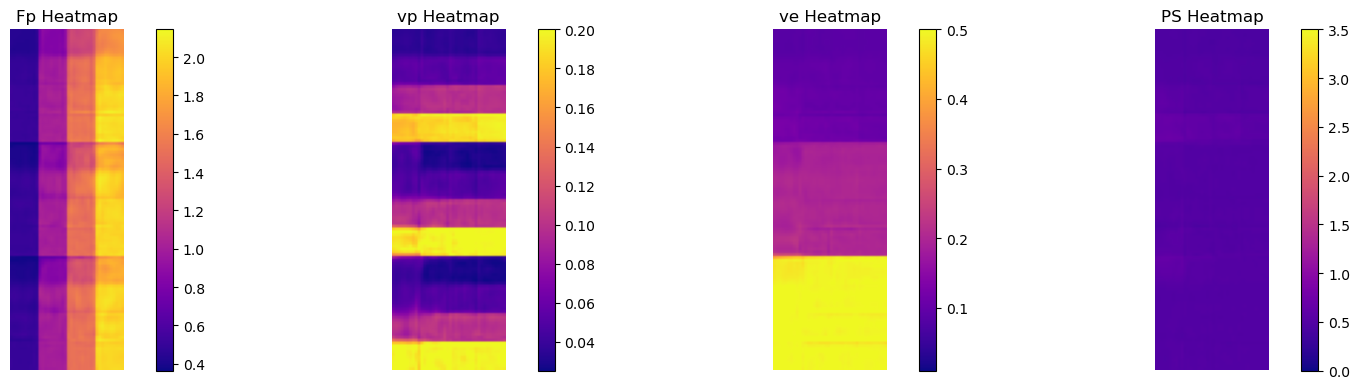

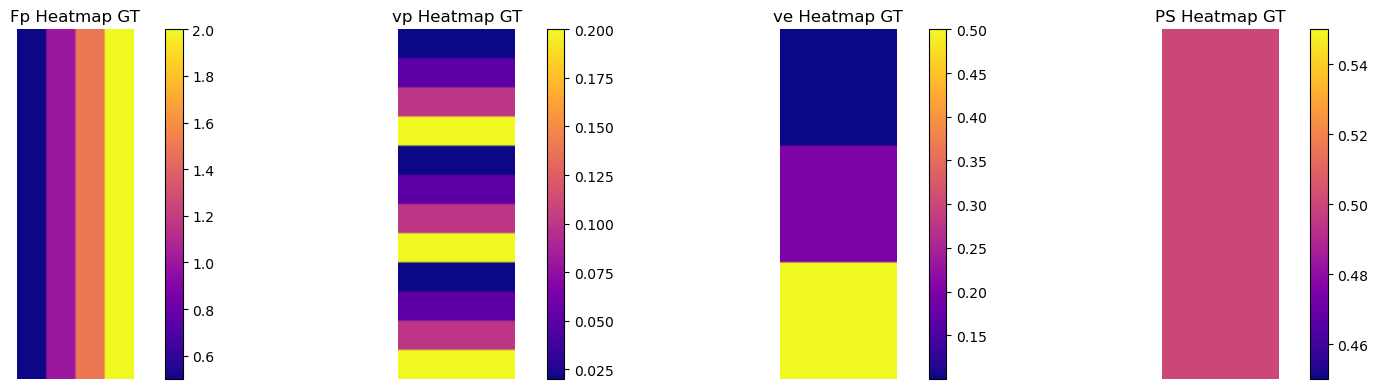

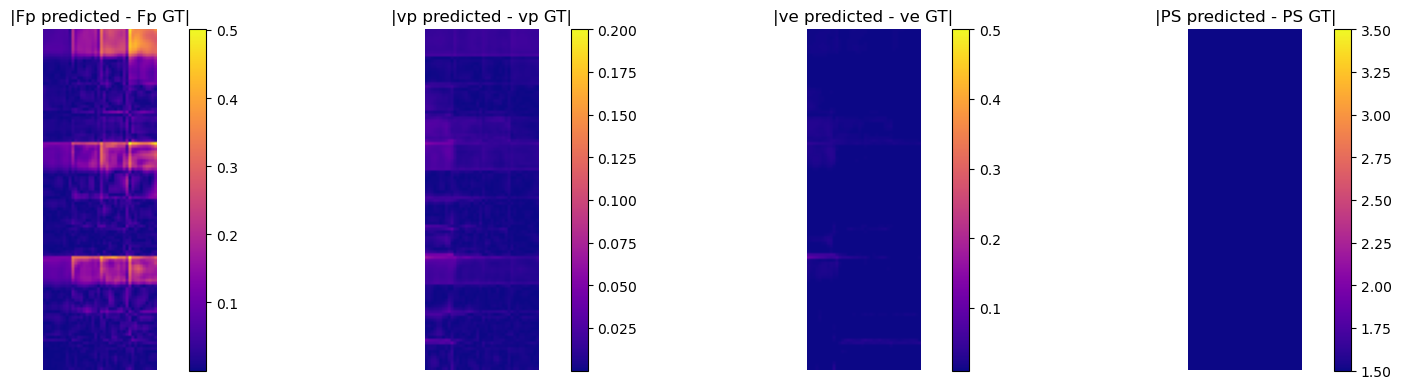

[[644.76104164 329.25713491 169.11220956]]


In [3]:
def main(seed_value, PS_slice):    
    t = time.time()
    # hard coded. later will add the config!
    aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(-1, PS_slice, 17.5) # type: ignore
    model_aif, model_myo, model_ode, total_losses, cost_list, nmse_per_param, ssim_per_param = train_pinn(myo_curves, myo_pars, aif_time, aif, 
               epochs=1000, lr=1e-4, batch_size=256, seed_value=seed_value,
               num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
               num_layers_myo=5,dim_hidden_myo = 128, w0_myo=20, w0_initial_myo=25,
               num_layers_2cxm=4, dim_hidden_2cxm=256,w0_2cxm=10, w0_initial_2cxm=20,
               loss_w_aif = 5.0, loss_w_myo = 10.0, loss_w_2cxm = 0.01)
    
    # save models

    return model_aif, model_myo, model_ode, total_losses, cost_list, nmse_per_param, ssim_per_param

N = 10 #30
seed_value_list = np.arange(0,1)
final_loss = np.zeros(shape=(1, 3)) # 4 : 1000 epochs (30, 100, 300, 1000)
print(np.shape(final_loss))
seed_index = 0
PS_slice = 0
for seed_value in seed_value_list:
    #lr_adam_p, lr_adam_e, lr_adam_ode = lr_adam, lr_adam, lr_adam
    model_aif, model_myo, model_ode, total_losses, cost_list, nmse_per_param, ssim_per_param = main(seed_value, PS_slice)
    cost_sum = np.sum(np.array(cost_list), axis=1) # Fp+ve+vp+ps losses
    final_loss[seed_index][0] = cost_sum[29]
    final_loss[seed_index][1] = cost_sum[99]
    final_loss[seed_index][2] = cost_sum[299]
    #final_loss[seed_index][3] = cost_sum[999]
    
    seed_index += 1
print(final_loss)


C:\Users\beren\AppData\Local\Temp\ipykernel_26904\3850424133.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


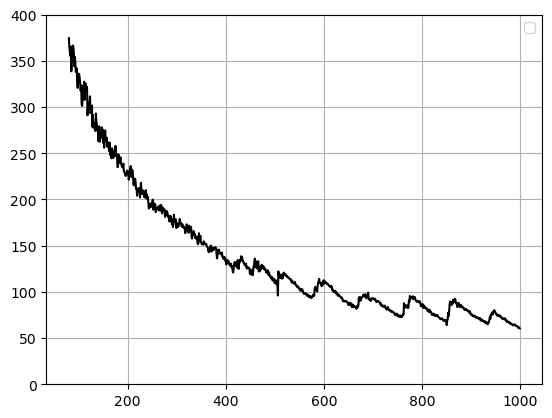

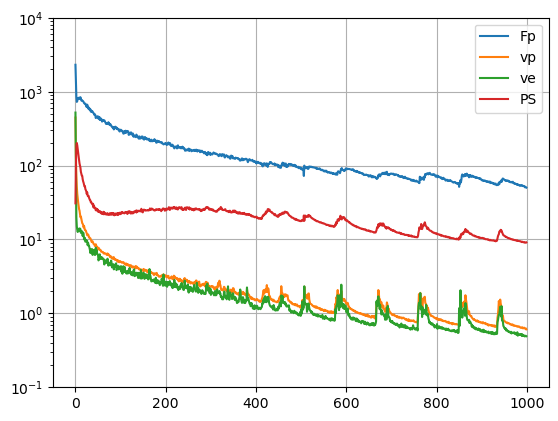

60.47558978199959


In [9]:
cost_sum = np.sum(np.array(cost_list), axis=1)
#plt.plot(cost_sum, color="black")
plt.plot(np.arange(80, len(cost_sum[80:])+80), cost_sum[80:], color="black")
plt.legend()
plt.grid()
plt.ylim(0,400) #plt.ylim(0,cost_sum[80])
plt.show()

labels = ["Fp", "vp", "ve", "PS"] 
i = 0
for list in cost_list.T:
    plt.plot(list, label=labels[i])
    i += 1
plt.yscale("log")
plt.ylim(1e-1, 1e4)
plt.legend()
plt.grid()
plt.show()

print(np.sum(cost_list[-1]))

C:\Users\beren\AppData\Local\Temp\ipykernel_26904\1111498113.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


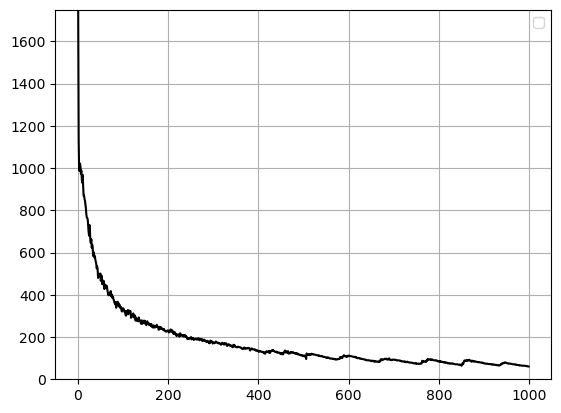

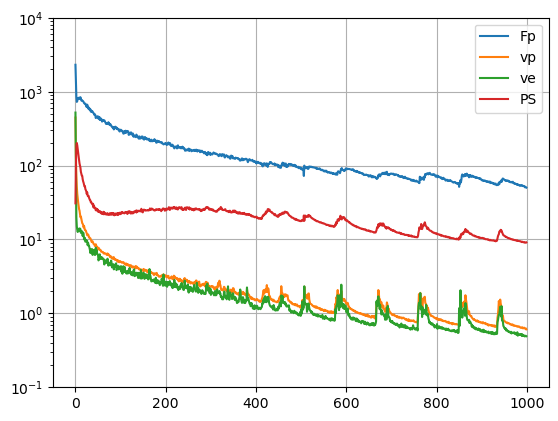

60.47558978199959


In [7]:
cost_sum = np.sum(np.array(cost_list), axis=1)
plt.plot(cost_sum, color="black")
plt.legend()
plt.grid()
plt.ylim(0,1750)
plt.show()

labels = ["Fp", "vp", "ve", "PS"] 
i = 0
for list in cost_list.T:
    plt.plot(list, label=labels[i])
    i += 1
plt.yscale("log")
plt.ylim(1e-1, 1e4)
plt.legend()
plt.grid()
plt.show()

print(np.sum(cost_list[-1]))

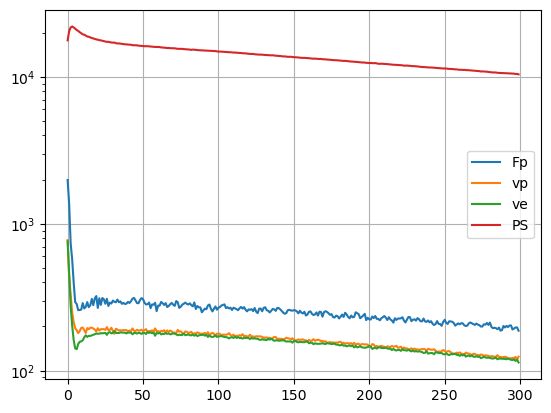

In [ ]:
labels = ["Fp", "vp", "ve", "PS"] 
i = 0
for list in cost_list.T:
    plt.plot(list, label=labels[i])
    i += 1
plt.yscale("log")
plt.legend()
plt.grid()

In [ ]:
print(final_loss.T)

[[17541.52294922 19963.49514771 18710.7769165  21148.58654785
  17778.70968628]
 [14994.31187439 17774.96510315 16466.83572388 18794.00839233
  15520.9875946 ]
 [ 9909.12086487 12405.21775818 11178.41467285 13514.50634766
  10820.87388611]]


In [ ]:
# PS=1.5
x = [[4176.50234222 5518.88923645 4995.8151474  5893.53321838 4398.11760712]
 [2475.26597214 3530.18241882 3242.30053711 3982.68917847 2812.70374298]
 [ 935.58398819 1273.2498703  1179.50036621 1629.47371674 1126.70838356]]

y = [[17541.52294922 19963.49514771 18710.7769165  21148.58654785
  17778.70968628]
 [14994.31187439 17774.96510315 16466.83572388 18794.00839233
  15520.9875946 ]
 [ 9909.12086487 12405.21775818 11178.41467285 13514.50634766
  10820.87388611]]


In [2]:
def round_sig(x, n=3):
    return float(f"{x:.{n}g}")

<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:36: SyntaxWarning: invalid escape sequence '\m'
<>:34: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:36: SyntaxWarning: invalid escape sequence '\m'
C:\Users\beren\AppData\Local\Temp\ipykernel_14320\1522351630.py:34: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, fl_30_full,  label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
C:\Users\beren\AppData\Local\Temp\ipykernel_14320\1522351630.py:35: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, fl_100_full,  label="epochs=100, $\mu$={}, cv={}".format(mu_100, cv_100))
C:\Users\beren\AppData\Local\Temp\ipykernel_14320\1522351630.py:36: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(seed_values, fl_300_full,  label="epochs=300, $\mu$={}, cv={}".format(mu_300, cv_300))


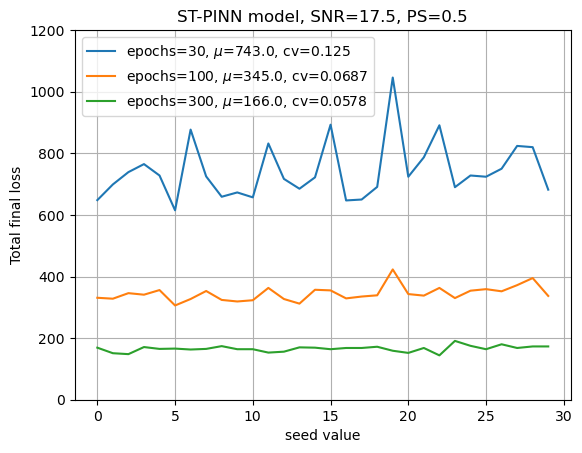

In [7]:
fl_09_30 = [648, 699, 739, 765, 728, 615, 877, 725, 659, 673]
fl_1019_30 = [657, 832, 717, 685, 722, 893, 647, 650, 691, 1046]
fl_2029_30 = [724, 787, 891, 690, 728, 724, 750, 824, 820, 682]

fl_09_100 = [331, 328, 346, 341, 356, 306, 327, 353, 324, 319]
fl_1019_100 = [323, 363, 327, 312, 357, 355, 329, 335, 339, 423]
fl_2029_100 = [343, 338, 363, 330, 354, 359, 352, 372, 395, 337]

fl_09_300 = [169, 151, 148, 171, 165, 166, 163, 165, 174, 164]
fl_1019_300 = [164, 153, 156, 170, 169, 164, 168, 168, 172, 159]
fl_2029_300 = [152, 168, 144, 191, 175, 164, 180, 168, 173, 173]

fl_30_full = []
for list_ in [fl_09_30, fl_1019_30, fl_2029_30]:
    for elt in list_:
        fl_30_full.append(elt)
fl_100_full = []
for list_ in [fl_09_100, fl_1019_100, fl_2029_100]:
    for elt in list_:
        fl_100_full.append(elt)
fl_300_full = []
for list_ in [fl_09_300, fl_1019_300, fl_2029_300]:
    for elt in list_:
        fl_300_full.append(elt)

mu_30 = round_sig(np.mean(fl_30_full))
mu_100 = round_sig(np.mean(fl_100_full))
mu_300 = round_sig(np.mean(fl_300_full))
cv_30 =  round_sig( np.std(fl_30_full)/np.abs(np.mean(fl_30_full)) )
cv_100 = round_sig( np.std(fl_100_full)/np.abs(np.mean(fl_100_full)) )
cv_300 = round_sig( np.std(fl_300_full)/np.abs(np.mean(fl_300_full)) )

seed_values = np.arange(0, 30)
plt.plot(seed_values, fl_30_full,  label="epochs=30, $\mu$={}, cv={}".format(mu_30, cv_30))
plt.plot(seed_values, fl_100_full,  label="epochs=100, $\mu$={}, cv={}".format(mu_100, cv_100))
plt.plot(seed_values, fl_300_full,  label="epochs=300, $\mu$={}, cv={}".format(mu_300, cv_300))

plt.grid()
plt.xlabel("seed value")
plt.ylabel("Total final loss")
plt.title("ST-PINN model, SNR=17.5, PS=0.5")
plt.ylim(0,1200)
plt.legend()

In [ ]:
# example

fl_30_full = []
for list_ in [fl_09_30, fl_1019_30]:
    for elt in list_:
        fl_30_full.append(elt)
fl_100_full = []
for list_ in [fl_09_100, fl_1019_100]:
    for elt in list_:
        fl_100_full.append(elt)

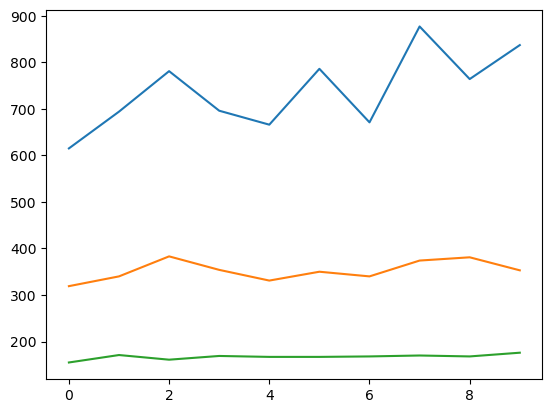

In [ ]:
x = [615, 694, 781, 696, 666, 786, 671, 877, 764, 837]
y = [319, 340, 383, 354, 331, 350, 340, 374, 381, 353]
z = [155, 171, 161, 169, 167, 167, 168, 170, 168, 176]

seed_values = np.arange(0, 10)
plt.plot(seed_values, x)
plt.plot(seed_values, y)
plt.plot(seed_values, z)

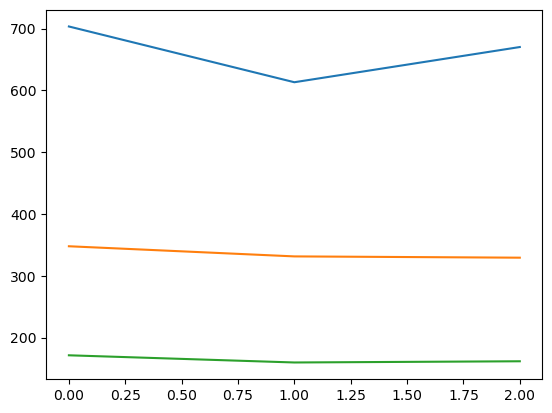

In [ ]:
fl_02_30_rand = [703.38617992, 613.15372753, 670.12205219]
fl_02_100_rand = [347.71082163, 331.2988174,  329.22406507]
fl_02_300_rand = [171.25563192, 159.63383651, 161.58774638]

seed_values = np.arange(0, 3)
plt.plot(seed_values, fl_02_30)
plt.plot(seed_values, fl_02_100)
plt.plot(seed_values, fl_02_300)

In [ ]:
print( np.shape(nmse_per_param) )
print("NMSE: Fp, vp, ve, PS")
print(nmse_per_param)
print( )
print("SSIM: Fp, vp, ve, PS")
print(ssim_per_param)

(4,)
NMSE: Fp, vp, ve, PS
[0.006263702392578125, 0.010338460769734718, 0.0010805712391932806, 0.006470518112182617]

SSIM: Fp, vp, ve, PS
[0.8685823678970337, 0.8479853868484497, 0.9110414981842041, 0.4215411841869354]


[[1957.78540039  715.8137207   621.81018066  104.05349731]
 [1910.50561523  235.04907227  219.92053223   44.17261505]
 [1386.9552002    79.17668152   60.71957016  161.12936401]
 [1123.11425781   57.60083008   22.84103775  234.572052  ]
 [1000.46014404   52.16416931   18.66140366  240.0697937 ]
 [1011.62036133   43.06641006   19.70940781  228.75228882]
 [1011.83862305   38.58185577   20.66687965  209.37310791]
 [1006.2310791    35.25560379   21.01665115  192.06698608]
 [1001.28375244   34.04793167   19.77981377  173.074646  ]
 [1007.34240723   32.0716095    18.66414642  162.72616577]
 [ 972.30773926   30.09918785   18.05295181  151.38009644]
 [ 987.51348877   28.37779045   17.75895119  143.92268372]
 [ 951.85247803   27.98227882   16.15118027  134.22650146]
 [ 942.12487793   26.32483101   17.11503792  126.5997467 ]
 [ 916.70489502   25.23072243   17.10808563  121.79241943]
 [ 901.80767822   24.07002068   16.95960045  116.97875977]
 [ 869.8145752    23.15544891   18.12903214  112.6323394

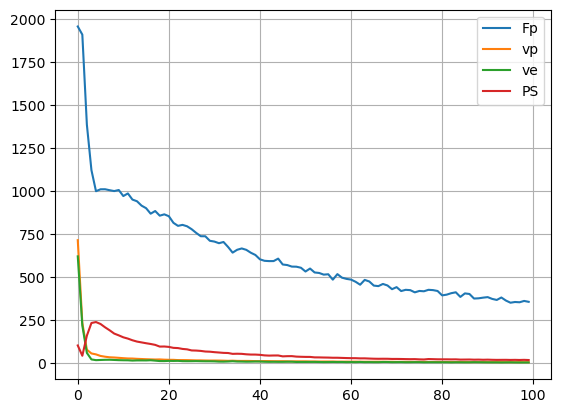

In [ ]:
print(cost_list)

labels= ["Fp", "vp", "ve", "PS"]
for i in np.arange(0, 4):
    plt.plot(cost_list.T[i], label = labels[i])
plt.legend()
plt.grid()


In [ ]:
def main(epochs, seed_value):    
    t = time.time()
    # hard coded. later will add the config!
    aif_time, aif, myo_curves, myo_pars = make_dro_no_delay(tf_format=-1, ps_slice=0, snr=17.5) # type: ignore
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = train_pinn(myo_curves, myo_pars, aif_time, aif, 
            epochs=epochs, lr=3e-5, batch_size=512, seed_value=seed_value,
            num_layers_aif=5, dim_hidden_aif=64, w0_aif=25, w0_initial_aif=15,
            num_layers_myo=5, dim_hidden_myo = 128, w0_myo=20, w0_initial_myo=25,
            num_layers_2cxm=5, dim_hidden_2cxm=512, w0_2cxm=10, w0_initial_2cxm=20,
            loss_w_aif=5.0, loss_w_myo = 10.0, loss_w_ode_p=0.1, loss_w_ode_e=0.3,
    ) #added two last losses
    
    # # save models
    # torch.save(model_aif.state_dict(), "model_aif.pth")
    # torch.save(model_myo.state_dict(), "model_myo.pth")
    # torch.save(model_ode.state_dict(), "model_ode.pth")
    return model_aif, model_e, model_p, model_ode, total_losses, cost_list

ps_slice=0
#loss_w_ode_p = 10.0
epochs = 300
seed_values = np.arange(0,2)
final_loss = np.zeros(shape=(len(seed_values), 5))

seed_index = 0
for seed_value in seed_values:
    loss_w_ode_p = 0.1
    loss_w_ode_e = 0.3
    model_aif, model_e, model_p, model_ode, total_losses, cost_list = main(epochs, seed_value)

    cost_sum = np.sum(np.array(cost_list), axis=1)

    final_loss[seed_index][0] = cost_sum[29]
    final_loss[seed_index][1] = cost_sum[99]
    final_loss[seed_index][2] = cost_sum[299]
    #final_loss[seed_index][3] = cost_sum[999]
    #final_loss[seed_index][4] = cost_sum[2999]

    seed_index += 1
    
    if 0==1:
        cost_sum = np.sum(np.array(cost_list), axis=1)
        plt.plot(cost_sum)
        plt.grid()
        plt.show()
        print(cost_sum[-1])

# plt.plot(seed_values, final_loss[0])
# plt.plot(seed_values, final_loss[1])


TypeError: train_pinn() got an unexpected keyword argument 'loss_w_ode_p'

In [ ]:
main()

NameError: name 'main' is not defined